# Bonus · Week 1, rebuilt in code (5 marks, optional)

Count the 3s. In Week 1 you did it twice; this notebook builds the four panels and then charts how long **five classmates** take to count the targets in each.

1. Run the first cells: they draw the four panels (`outputs/popout_panels.png`) and give each participant a randomised panel order.
2. Show the panels to five people, time them, and type the seconds into the **RESULTS** cell.
3. Set `USE_DEMO_DATA = False` and re-run for your real chart.

> **I cannot run this experiment for you.** Until you enter real times the chart uses clearly-labelled **DEMO** numbers, watermarked on the figure and saved under a different file name, so they cannot be handed in by accident. The results you report must be your own measurements. Results that disagree with the textbook score full marks if reported honestly.

In [ ]:
# --- Setup: finds vizlib.py and data/ wherever this notebook is saved ---------------
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

def find_assignments_dir():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        for cand in (p, p / "assignments", p / "week3" / "assignments"):
            if (cand / "vizlib.py").exists() and (cand / "data").is_dir():
                return cand
    raise FileNotFoundError(
        "Could not find vizlib.py + data/. Save this notebook inside "
        "week3/assignments/ (next to vizlib.py) - see README.md.")

ROOT = find_assignments_dir()
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"
OUT = ROOT / "outputs"            # every PNG this notebook writes lands here
OUT.mkdir(exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from vizlib import (PALETTE, MARKERS, style_defaults, save_fig, lie_factor,
                    lie_verdict, simulate_cvd, worst_pair, verdict, delta_e)

style_defaults()                  # house look, set once (slide 26)
BLUE, ORANGE, GREEN = PALETTE["series"]
print("ROOT:", ROOT)

ROOT: week3/assignments


wrote week3/assignments/outputs/popout_panels.png


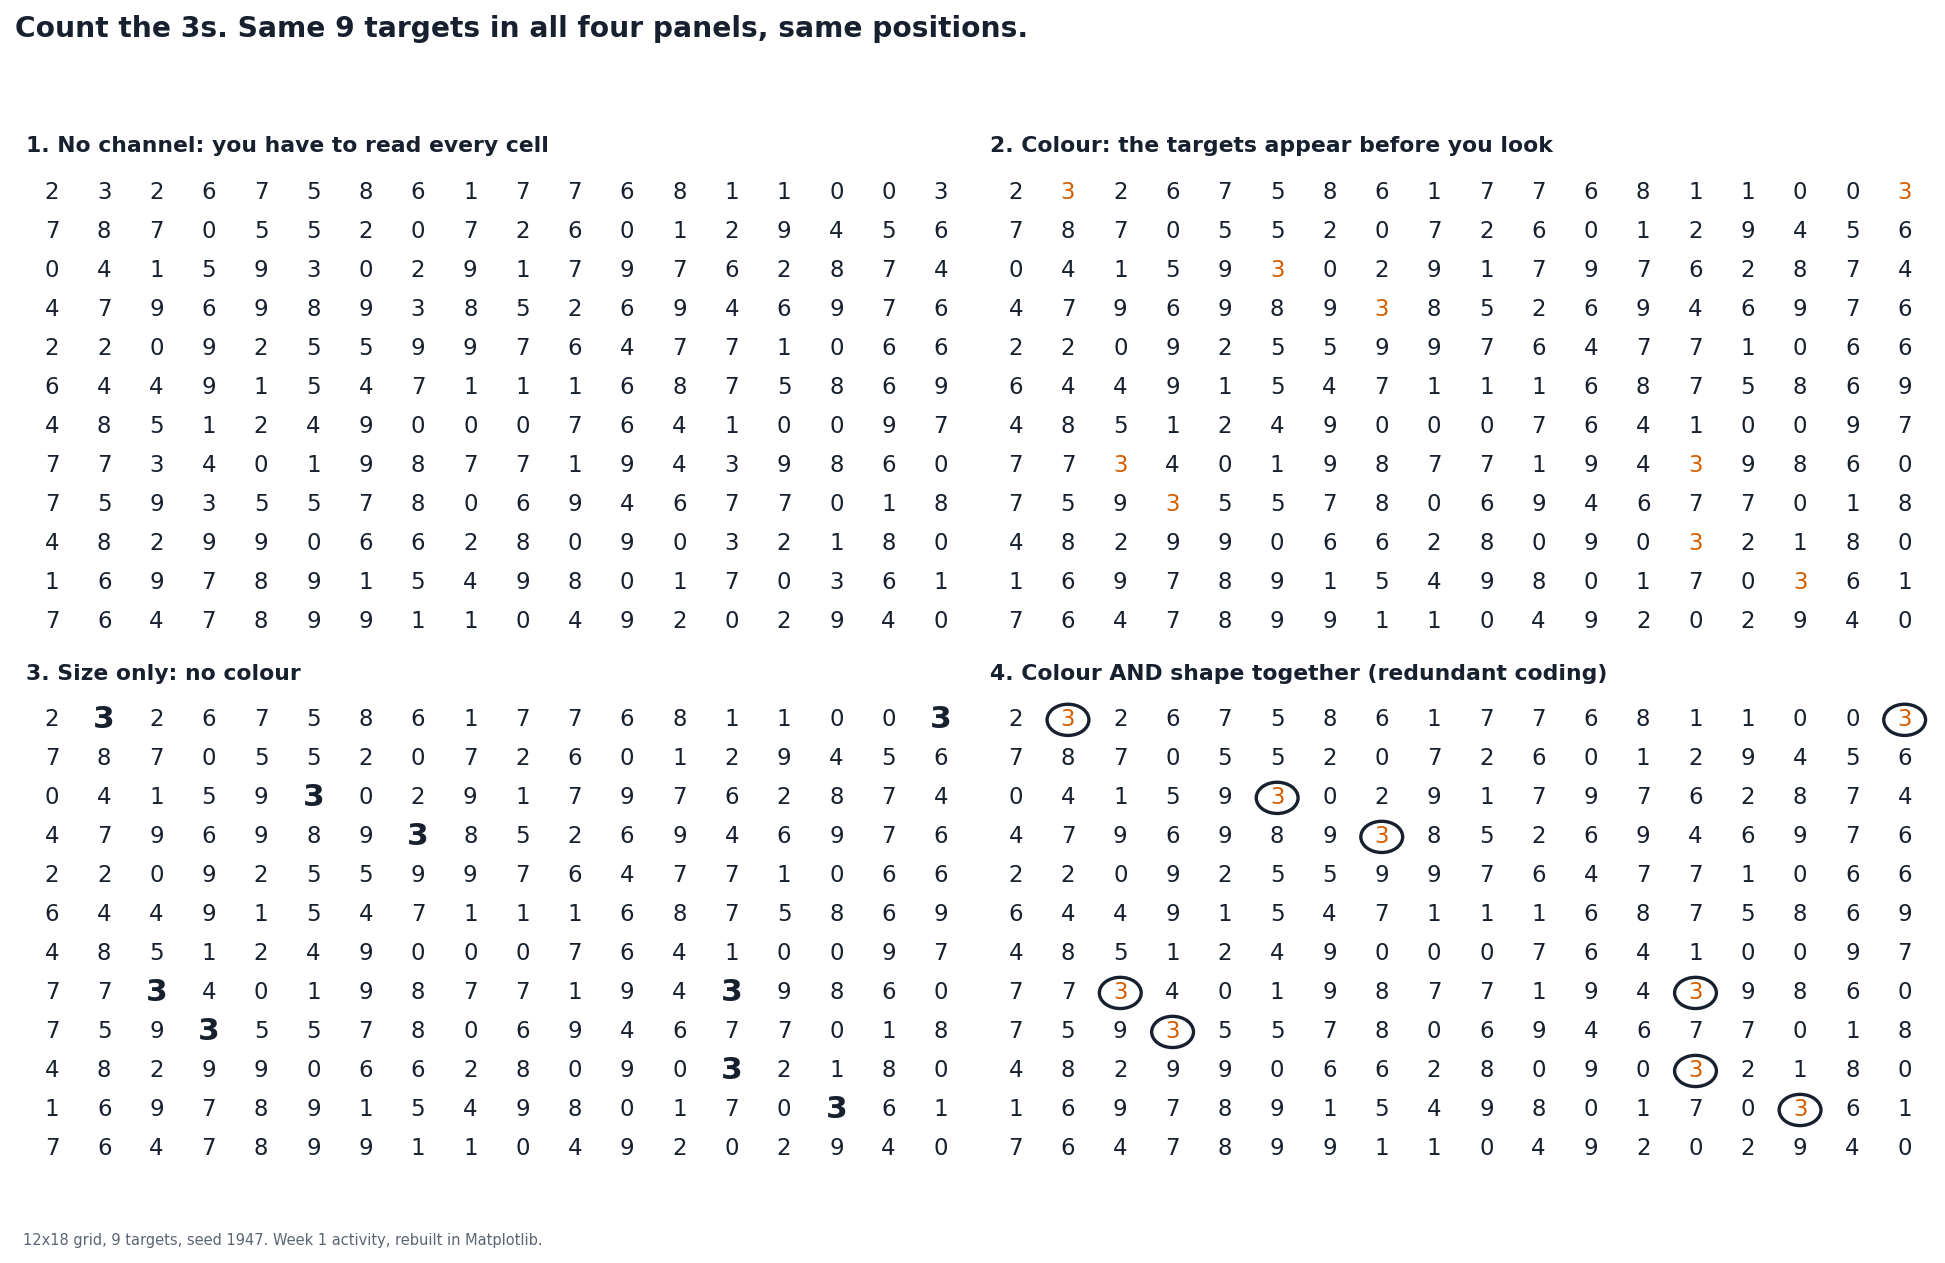

In [ ]:
# ---------------------------------------------------------------- the grid (from starter/popout.py)
ROWS, COLS, TARGET, N_TARGETS, SEED = 12, 18, "3", 9, 1947

def make_grid(seed=SEED):
    """A grid of digits with exactly N_TARGETS threes, in fixed positions."""
    rng = np.random.default_rng(seed)
    others = [d for d in "0123456789" if d != TARGET]
    grid = np.array([[rng.choice(others) for _ in range(COLS)] for _ in range(ROWS)], dtype=object)
    for k in rng.choice(ROWS * COLS, size=N_TARGETS, replace=False):
        grid[k // COLS, k % COLS] = TARGET
    return grid

def draw(ax, grid, title, colour=False, size=False, shape=False):
    """colour -> targets get the highlight hue; size -> drawn larger; shape -> a ring behind them."""
    ax.set_xlim(-0.5, COLS - 0.5); ax.set_ylim(-0.5, ROWS - 0.5)
    ax.invert_yaxis(); ax.axis("off"); ax.set_title(title, fontsize=10.5, loc="left")
    for r in range(ROWS):
        for c in range(COLS):
            d = grid[r, c]; hit = d == TARGET
            if shape and hit:
                ax.add_patch(plt.Circle((c, r), 0.40, fill=False, edgecolor=PALETTE["ink"], lw=1.6))
            ax.text(c, r, d, ha="center", va="center",
                    fontsize=15 if (size and hit) else 11,
                    fontweight="bold" if (size and hit) else "normal",
                    color=PALETTE["highlight"] if (colour and hit) else PALETTE["ink"])

grid = make_grid()
fig, ax = plt.subplots(2, 2, figsize=(13.0, 8.0))
draw(ax[0, 0], grid, "1. No channel: you have to read every cell")                              # given
draw(ax[0, 1], grid, "2. Colour: the targets appear before you look", colour=True)              # given
draw(ax[1, 0], grid, "3. Size only: no colour", size=True)                                      # TODO 1, done
draw(ax[1, 1], grid, "4. Colour AND shape together (redundant coding)", colour=True, shape=True)  # TODO 2, done
fig.suptitle(f"Count the {TARGET}s. Same {N_TARGETS} targets in all four panels, same positions.",
             x=0.006, ha="left", fontsize=13.5, fontweight="bold", color=PALETTE["ink"])
fig.tight_layout(rect=[0, 0, 1, 0.94])
print("wrote", save_fig(fig, OUT / "popout_panels.png",
                        f"{ROWS}x{COLS} grid, {N_TARGETS} targets, seed {SEED}. Week 1 activity, rebuilt in Matplotlib."))
plt.show()

**Panel 3 (size only)** needs no colour: the targets are 15 pt bold against 11 pt regular. **Panel 4** puts a ring behind each target *and* colours it, so a reader with deuteranopia loses panel 2's cue but keeps panel 4's.

In [ ]:
# ---------------------------------------------------------------- randomised order per participant
PEOPLE = ["P1", "P2", "P3", "P4", "P5"]
ORDER_SEED = 2026
rng = np.random.default_rng(ORDER_SEED)
orders = pd.DataFrame({p: rng.permutation([1, 2, 3, 4]) for p in PEOPLE}, index=["1st", "2nd", "3rd", "4th"]).T
orders.index.name = "participant"
print("Show each participant the panels in THIS order (a different random order each):")
display(orders)

Show each participant the panels in THIS order (a different random order each):


,1st,2nd,3rd,4th
participant,,,,
P1,4,2,1,3
P2,1,2,3,4
P3,1,2,3,4
P4,2,3,4,1
P5,4,2,3,1


## RESULTS · type your stopwatch times here
Seconds to count the targets, one list per panel, in the order P1…P5. `CORRECT[p][i]` = did participant *i* count exactly 9?

In [ ]:
USE_DEMO_DATA = True          # <-- set to False once RESULTS below holds your REAL times

RESULTS = {                   # panel number: [P1, P2, P3, P4, P5] seconds
    1: [None, None, None, None, None],
    2: [None, None, None, None, None],
    3: [None, None, None, None, None],
    4: [None, None, None, None, None],
}
CORRECT = {1: [True] * 5, 2: [True] * 5, 3: [True] * 5, 4: [True] * 5}      # change any that miscounted

DEMO = {                      # INVENTED numbers, only so the chart code can be seen working
    1: [24.1, 31.5, 19.8, 27.0, 22.6],
    2: [3.2, 2.8, 4.1, 3.0, 3.6],
    3: [6.4, 5.1, 7.8, 5.9, 6.6],
    4: [3.4, 3.0, 3.9, 2.9, 3.5],
}
data = DEMO if USE_DEMO_DATA else RESULTS
if not USE_DEMO_DATA and any(v is None for lst in data.values() for v in lst):
    raise ValueError("Fill in all 20 times in RESULTS (4 panels x 5 people), or keep USE_DEMO_DATA = True.")
times = pd.DataFrame(data, index=PEOPLE); times.columns = [f"panel {c}" for c in times.columns]
display(times)

,panel 1,panel 2,panel 3,panel 4
P1,24.1,3.2,6.4,3.4
P2,31.5,2.8,5.1,3.0
P3,19.8,4.1,7.8,3.9
P4,27.0,3.0,5.9,2.9
P5,22.6,3.6,6.6,3.5


wrote week3/assignments/outputs/popout_experiment_DEMO.png


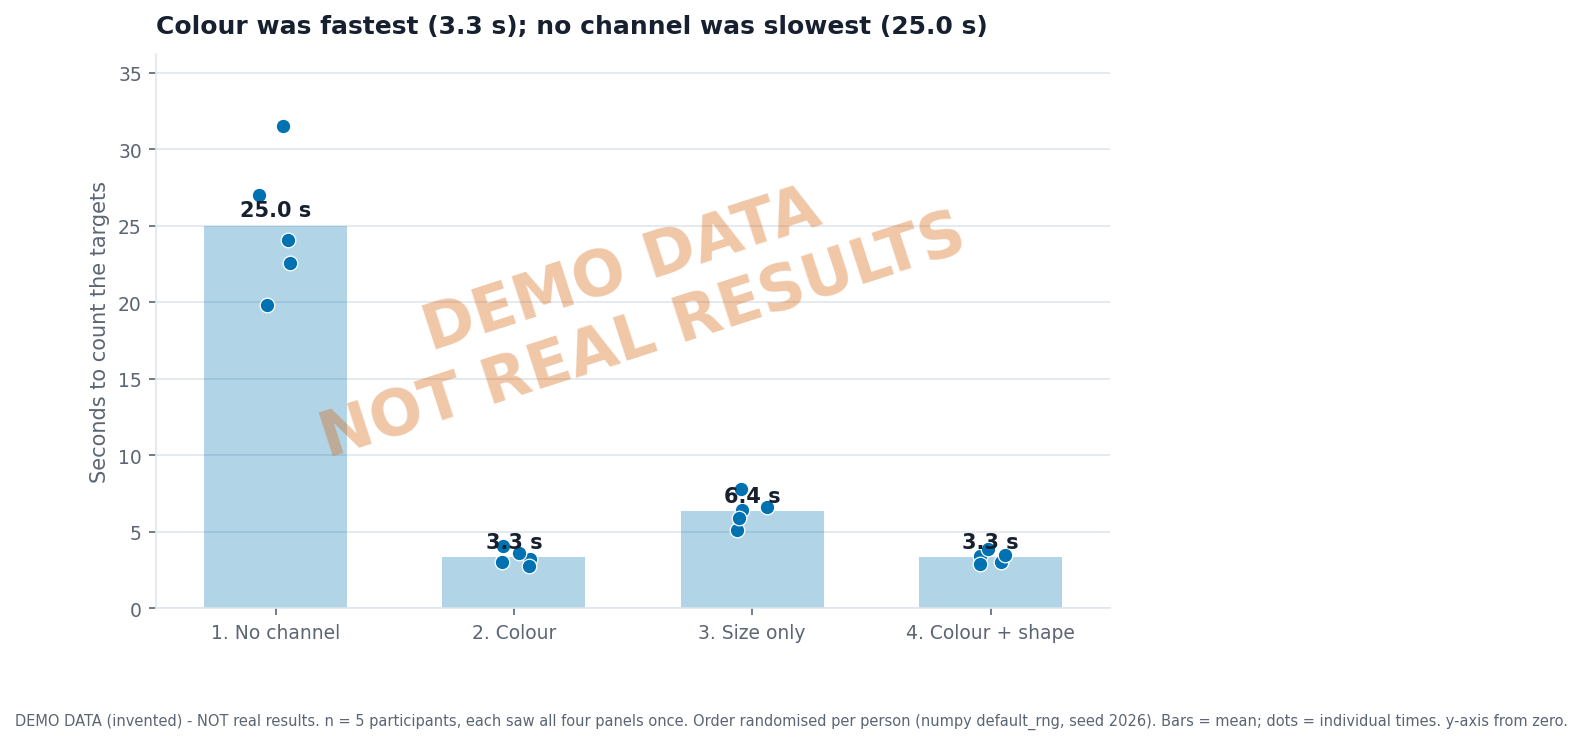

In [ ]:
# ---------------------------------------------------------------- the chart
LABELS = {"panel 1": "1. No channel", "panel 2": "2. Colour", "panel 3": "3. Size only", "panel 4": "4. Colour + shape"}
means = times.mean()
fastest, slowest = means.idxmin(), means.idxmax()
long = times.reset_index(names="participant").melt(id_vars="participant", var_name="panel", value_name="seconds")
long["panel"] = long.panel.map(LABELS)

fig, ax = plt.subplots(figsize=(8.2, 4.8))
xs = np.arange(4)
ax.bar(xs, means.values, color=BLUE, alpha=0.30, width=0.6, zorder=2)                     # faded bar = mean
sns.stripplot(data=long, x="panel", y="seconds", order=list(LABELS.values()), color=BLUE, size=7,
              jitter=0.08, edgecolor="white", linewidth=0.6, ax=ax, zorder=3)              # raw points
for i, m in enumerate(means.values):
    ax.text(i, m + 0.6, f"{m:.1f} s", ha="center", fontweight="bold", color=PALETTE["ink"])
ax.set_ylim(0, long.seconds.max() * 1.15)                                                  # zero baseline
ax.set_xlabel(""); ax.set_ylabel("Seconds to count the targets")
ax.grid(axis="x", visible=False)
title = (f"{LABELS[fastest].split('. ')[1]} was fastest ({means[fastest]:.1f} s); "
         f"{LABELS[slowest].split('. ')[1].lower()} was slowest ({means[slowest]:.1f} s)")
ax.set_title(title)
note = (f"n = 5 participants, each saw all four panels once. Order randomised per person "
        f"(numpy default_rng, seed {ORDER_SEED}). Bars = mean; dots = individual times. y-axis from zero.")
if USE_DEMO_DATA:
    ax.text(0.5, 0.55, "DEMO DATA\nNOT REAL RESULTS", transform=ax.transAxes, ha="center", va="center",
            fontsize=30, fontweight="bold", color=PALETTE["highlight"], alpha=0.35, rotation=18, zorder=5)
    note = "DEMO DATA (invented) - NOT real results. " + note
fname = "popout_experiment_DEMO.png" if USE_DEMO_DATA else "popout_experiment.png"
print("wrote", save_fig(fig, OUT / fname, note))
plt.show()

## Your three sentences
Draft generated from the numbers above. **Check it against your own data and rewrite it in your words.**

In [ ]:
p1, p2, p3, p4 = (means[f"panel {i}"] for i in range(1, 5))
tag = "[DEMO DATA] " if USE_DEMO_DATA else ""
accuracy = {f"panel {k}": f"{sum(v)}/5" for k, v in CORRECT.items()}
display(Markdown(f"""
{tag}**Fastest:** {LABELS[fastest]} ({means[fastest]:.1f} s on average). **Slowest:** {LABELS[slowest]} ({means[slowest]:.1f} s), about {means[slowest] / means[fastest]:.1f}x slower than the fastest.
**Redundant coding:** colour + shape ({p4:.1f} s) vs colour alone ({p2:.1f} s) is a difference of {p4 - p2:+.1f} s, so adding the second channel {"cost almost nothing" if abs(p4 - p2) < 0.5 else "changed speed noticeably, so say why"}.
Size alone ({p3:.1f} s) was {"slower" if p3 > p2 else "not slower"} than colour ({p2:.1f} s). Counted correctly (9 of 9): {accuracy}.
"""))


[DEMO DATA] **Fastest:** 2. Colour (3.3 s on average). **Slowest:** 1. No channel (25.0 s), about 7.5x slower than the fastest.
**Redundant coding:** colour + shape (3.3 s) vs colour alone (3.3 s) is a difference of +0.0 s, so adding the second channel cost almost nothing.
Size alone (6.4 s) was slower than colour (3.3 s). Counted correctly (9 of 9): {'panel 1': '5/5', 'panel 2': '5/5', 'panel 3': '5/5', 'panel 4': '5/5'}.
